In [1]:
import pandas as pd

df = pd.read_excel('data/dados.xlsx')
df["DBH"] = df["DAP"]

In [2]:
# Spliting datasets (training/testing)

from sklearn.model_selection import train_test_split

X = df[["DBH", "H"]] # DBH and Height
y = df["Volume"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
) # 70% for training; 30% for testing

train_idx = X_train.index
test_idx = X_test.index

df_train = df.loc[train_idx]
df_test = df.loc[test_idx]

In [3]:
# Descriptive statistics for training set

df_train.describe()

,DAP,H,Volume,DBH
count,470.000000,470.000000,470.000000,470.000000
mean,12.113858,9.285617,0.084043,12.113858
std,4.799246,3.647445,0.078292,4.799246
min,1.100000,1.500000,0.000435,1.100000
25%,9.000000,6.700000,0.026354,9.000000
50%,12.100000,9.350000,0.060486,12.100000
75%,15.100000,11.800000,0.114873,15.100000
max,24.900000,21.800000,0.425937,24.900000


In [4]:
# Descriptive statistics for testing set

df_test.describe()

,DAP,H,Volume,DBH
count,202.000000,202.000000,202.000000,202.000000
mean,11.893467,8.981188,0.082576,11.893467
std,5.116836,3.889102,0.081265,5.116836
min,1.600000,1.500000,0.000912,1.600000
25%,8.300000,5.825000,0.024152,8.300000
50%,11.700000,8.700000,0.051451,11.700000
75%,14.990141,11.900000,0.122741,14.990141
max,27.692960,20.900000,0.374133,27.692960


In [5]:
# Evaluation function

from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

def evaluate(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    bias = np.mean(y_pred - y_true)
    return r2, rmse, mae, bias

In [6]:
# Kopezky–Gehrhardt

# independent variable
X_train_kg = X_train["DBH"]**2
X_test_kg = X_test["DBH"]**2

from sklearn.linear_model import LinearRegression

model_kg = LinearRegression()

# reshape necessário
model_kg.fit(X_train_kg.values.reshape(-1, 1), y_train)

beta0 = model_kg.intercept_
beta1 = model_kg.coef_[0]

print(beta0, beta1)

-0.01769447103264199 0.0005994117979416696


In [7]:
# Predictions for Kopezky–Gehrhardt

pred_kg_train = model_kg.predict(X_train_kg.values.reshape(-1, 1))
pred_kg_test = model_kg.predict(X_test_kg.values.reshape(-1, 1))

r2_kg, rmse_kg, mae_kg, bias_kg = evaluate(y_test, pred_kg_test)

In [8]:
# Spurr

X_train_spurr = (X_train["DBH"]**2) * X_train["H"]
X_test_spurr = (X_test["DBH"]**2) * X_test["H"]

model_spurr = LinearRegression()

model_spurr.fit(
    X_train_spurr.values.reshape(-1, 1),
    y_train
)

beta0_spurr = model_spurr.intercept_
beta1_spurr = model_spurr.coef_[0]

print(beta0_spurr, beta1_spurr)

0.0063205385584581 4.037963434211971e-05


In [9]:
# Predictions for Spurr

pred_spurr_train = model_spurr.predict(
    X_train_spurr.values.reshape(-1, 1)
)

pred_spurr_test = model_spurr.predict(
    X_test_spurr.values.reshape(-1, 1)
)

r2_spurr, rmse_spurr, mae_spurr, bias_spurr = evaluate(y_test, pred_spurr_test)

In [10]:
# Schumacher–Hall

ln_D_train = np.log(X_train["DBH"])
ln_H_train = np.log(X_train["H"])
ln_V_train = np.log(y_train)

ln_D_test = np.log(X_test["DBH"])
ln_H_test = np.log(X_test["H"])

X_train_sh = np.column_stack([ln_D_train, ln_H_train])

model_sh = LinearRegression()
model_sh.fit(X_train_sh, ln_V_train)

beta0 = np.exp(model_sh.intercept_)
beta1 = model_sh.coef_[0]
beta2 = model_sh.coef_[1]

print(beta0, beta1, beta2)

0.00018101457410262496 1.624612365339851 0.8096210045975755


In [11]:
# Prediction for Schumacher–Hall

X_test_sh = np.column_stack([ln_D_test, ln_H_test])

ln_pred_test = model_sh.predict(X_test_sh)

ln_pred_train = model_sh.predict(X_train_sh)

# Correction factor
residuals = ln_V_train - ln_pred_train

SEE = np.std(residuals)

CF = np.exp((SEE**2) / 2)

# ... and then, prediction
pred_sh_test = np.exp(ln_pred_test) * CF
pred_sh_train = np.exp(ln_pred_train) * CF

r2_sh, rmse_sh, mae_sh, bias_sh = evaluate(y_test, pred_sh_test)


In [12]:
# Comparison table for classical models

results = pd.DataFrame({
    "Model": ["Kopezky–Gehrhardt", "Spurr", "Schumacher–Hall"],
    "R²": [r2_kg, r2_spurr, r2_sh],
    "RMSE": [rmse_kg, rmse_spurr, rmse_sh],
    "MAE": [mae_kg, mae_spurr, mae_sh],
    "Bias": [bias_kg, bias_spurr, bias_sh]
})

# arredondar para padrão de artigo
results = results.round({
    "R²": 3,
    "RMSE": 3,
    "MAE": 3,
    "Bias": 4
})

print(results)

               Model     R²   RMSE    MAE    Bias
0  Kopezky–Gehrhardt  0.881  0.028  0.019  0.0001
1              Spurr  0.857  0.031  0.016  0.0016
2    Schumacher–Hall  0.911  0.024  0.014 -0.0027


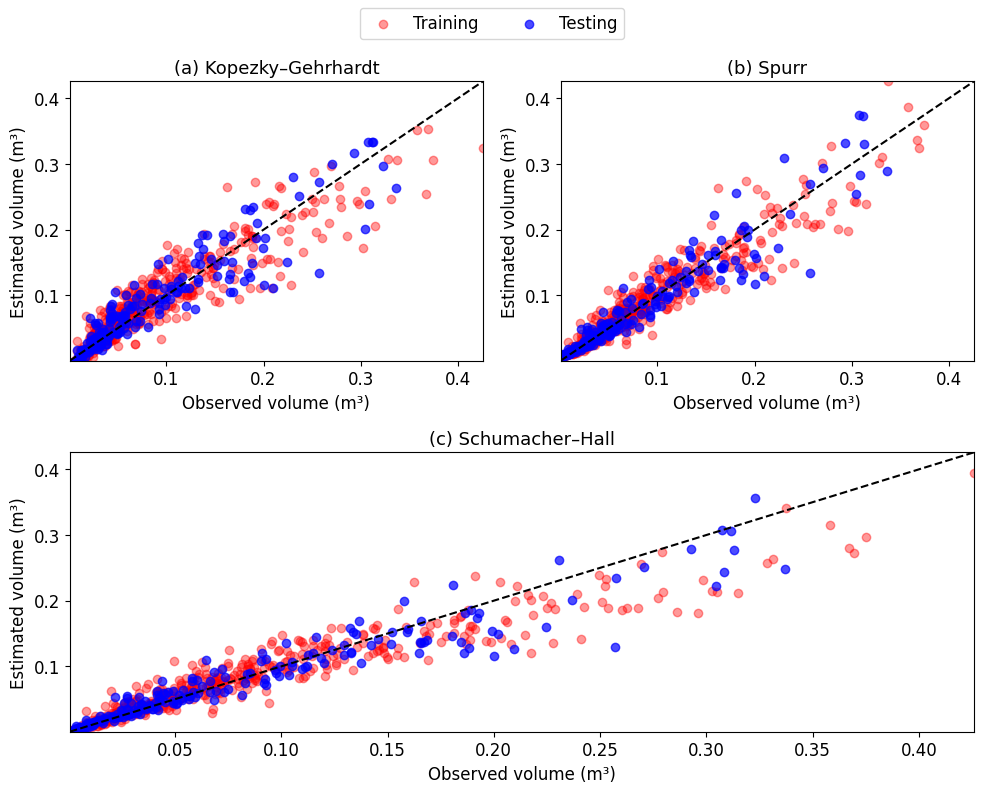

In [13]:
# Scatterplots for classical models

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
})

fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2)

min_val = min(y_test.min(), y_train.min())
max_val = max(y_test.max(), y_train.max())

def plot_model(ax, y_train, pred_train, y_test, pred_test, title):

    # 🔴 TRAIN
    ax.scatter(
        y_train,
        pred_train,
        color="red",
        alpha=0.4,
        label="Training"
    )

    # 🔵 TEST
    ax.scatter(
        y_test,
        pred_test,
        color="blue",
        alpha=0.7,
        label="Testing"
    )

    ax.plot([min_val, max_val], [min_val, max_val], 'k--')

    ax.set_title(title)
    ax.set_xlabel("Observed volume (m³)")
    ax.set_ylabel("Estimated volume (m³)")

    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)


# (a)
ax1 = fig.add_subplot(gs[0, 0])
plot_model(ax1, y_train, pred_kg_train, y_test, pred_kg_test,
           "(a) Kopezky–Gehrhardt")

# (b)
ax2 = fig.add_subplot(gs[0, 1])
plot_model(ax2, y_train, pred_spurr_train, y_test, pred_spurr_test,
           "(b) Spurr")

# (c) centralized
ax3 = fig.add_subplot(gs[1, :])
plot_model(ax3, y_train, pred_sh_train, y_test, pred_sh_test,
           "(c) Schumacher–Hall")

# single label
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

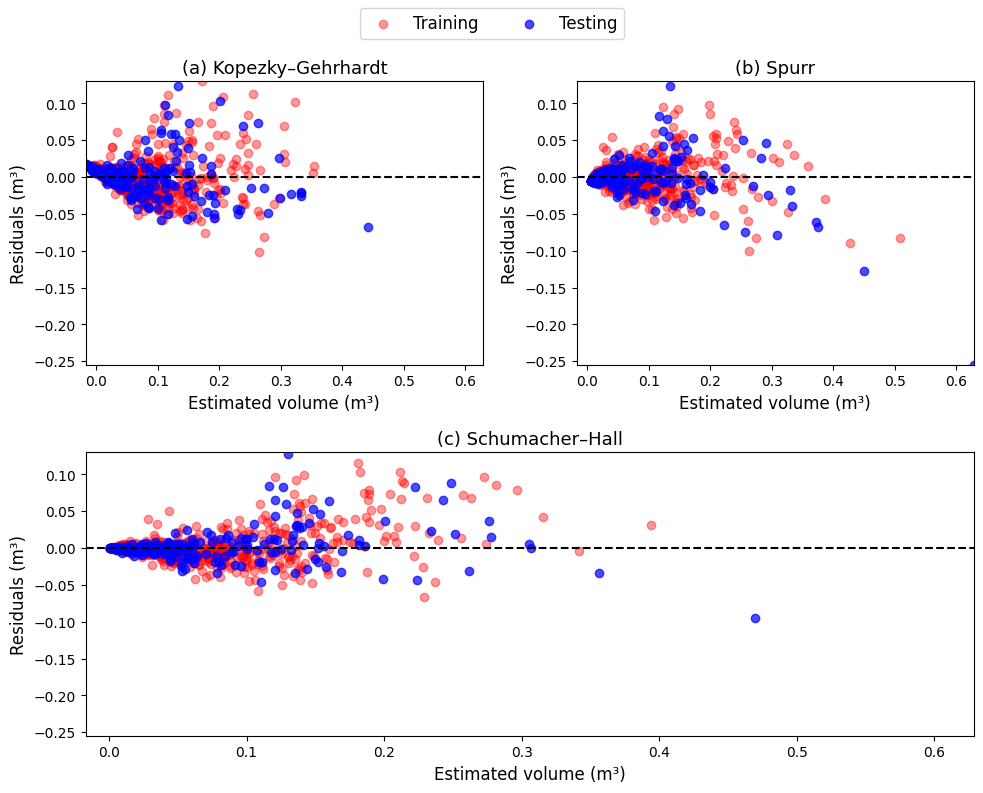

In [14]:
# Residuals for classical models

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

res_kg_train = y_train - pred_kg_train
res_kg_test = y_test - pred_kg_test

res_spurr_train = y_train - pred_spurr_train
res_spurr_test = y_test - pred_spurr_test

res_sh_train = y_train - pred_sh_train
res_sh_test = y_test - pred_sh_test

# Global limits
min_x = min(pred_kg_train.min(), pred_kg_test.min(),
            pred_spurr_train.min(), pred_spurr_test.min(),
            pred_sh_train.min(), pred_sh_test.min())

max_x = max(pred_kg_train.max(), pred_kg_test.max(),
            pred_spurr_train.max(), pred_spurr_test.max(),
            pred_sh_train.max(), pred_sh_test.max())

min_y = min(res_kg_train.min(), res_kg_test.min(),
            res_spurr_train.min(), res_spurr_test.min(),
            res_sh_train.min(), res_sh_test.min())

max_y = max(res_kg_train.max(), res_kg_test.max(),
            res_spurr_train.min(), res_spurr_test.min(),
            res_sh_train.min(), res_sh_test.min())

def plot_residuals(ax, pred_train, res_train, pred_test, res_test, title):

    # 🔴 TRAIN
    ax.scatter(
        pred_train,
        res_train,
        color="red",
        alpha=0.4,
        label="Training"
    )

    # 🔵 TEST
    ax.scatter(
        pred_test,
        res_test,
        color="blue",
        alpha=0.7,
        label="Testing"
    )

    ax.axhline(0, color='black', linestyle='--')

    ax.set_title(title)
    ax.set_xlabel("Estimated volume (m³)")
    ax.set_ylabel("Residuals (m³)")

    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)


fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2)

# (a)
ax1 = fig.add_subplot(gs[0, 0])
plot_residuals(ax1,
               pred_kg_train, res_kg_train,
               pred_kg_test, res_kg_test,
               "(a) Kopezky–Gehrhardt")

# (b)
ax2 = fig.add_subplot(gs[0, 1])
plot_residuals(ax2,
               pred_spurr_train, res_spurr_train,
               pred_spurr_test, res_spurr_test,
               "(b) Spurr")

# (c) centralized
ax3 = fig.add_subplot(gs[1, :])
plot_residuals(ax3,
               pred_sh_train, res_sh_train,
               pred_sh_test, res_sh_test,
               "(c) Schumacher–Hall")

# single label
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [15]:
# Random Forest

from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    random_state=42
)

model_rf.fit(X_train, y_train)

pred_rf_train = model_rf.predict(X_train)
pred_rf_test = model_rf.predict(X_test)

r2_rf, rmse_rf, mae_rf, bias_rf = evaluate(y_test, pred_rf_test)

In [16]:
# Support Vector Machine

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

model_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel='rbf', C=100, gamma=0.1))
])

model_svm.fit(X_train, y_train)

pred_svm_train = model_svm.predict(X_train)
pred_svm_test = model_svm.predict(X_test)

r2_svm, rmse_svm, mae_svm, bias_svm = evaluate(y_test, pred_svm_test)

In [17]:
# Artificial Neural Network

from sklearn.neural_network import MLPRegressor

model_ann = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(50, 50),
        max_iter=2000,
        random_state=42
    ))
])

model_ann.fit(X_train, y_train)

pred_ann_train = model_ann.predict(X_train)
pred_ann_test = model_ann.predict(X_test)

r2_ann, rmse_ann, mae_ann, bias_ann = evaluate(y_test, pred_ann_test)

In [18]:
# XGBoost

from xgboost import XGBRegressor

model_xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)

model_xgb.fit(X_train, y_train)

pred_xgb_train = model_xgb.predict(X_train)
pred_xgb_test = model_xgb.predict(X_test)

r2_xgb, rmse_xgb, mae_xgb, bias_xgb = evaluate(y_test, pred_xgb_test)

In [19]:
# Comparison table for ML algorithms

results_all = pd.DataFrame({
    "Model": [
        "Kopezky–Gehrhardt",
        "Spurr",
        "Schumacher–Hall",
        "Random Forest",
        "Support Vector Machine",
        "Artificial Neural Network",
        "XGBoost"
    ],
    "Type": [
        "Classical",
        "Classical",
        "Classical",
        "ML",
        "ML",
        "ML",
        "ML"
    ],
    "R²": [
        r2_kg,
        r2_spurr,
        r2_sh,
        r2_rf,
        r2_svm,
        r2_ann,
        r2_xgb
    ],
    "RMSE": [
        rmse_kg,
        rmse_spurr,
        rmse_sh,
        rmse_rf,
        rmse_svm,
        rmse_ann,
        rmse_xgb
    ],
    "MAE": [
        mae_kg,
        mae_spurr,
        mae_sh,
        mae_rf,
        mae_svm,
        mae_ann,
        mae_xgb
    ],
    "Bias": [
        bias_kg,
        bias_spurr,
        bias_sh,
        bias_rf,
        bias_svm,
        bias_ann,
        bias_xgb
    ]
})

# arredondamento padrão artigo
results_all = results_all.round({
    "R²": 3,
    "RMSE": 3,
    "MAE": 3,
    "Bias": 4
})

print(results_all)

                       Model       Type     R²   RMSE    MAE    Bias
0          Kopezky–Gehrhardt  Classical  0.881  0.028  0.019  0.0001
1                      Spurr  Classical  0.857  0.031  0.016  0.0016
2            Schumacher–Hall  Classical  0.911  0.024  0.014 -0.0027
3              Random Forest         ML  0.912  0.024  0.015 -0.0006
4     Support Vector Machine         ML  0.437  0.061  0.056  0.0504
5  Artificial Neural Network         ML  0.882  0.028  0.017 -0.0017
6                    XGBoost         ML  0.895  0.026  0.016  0.0006


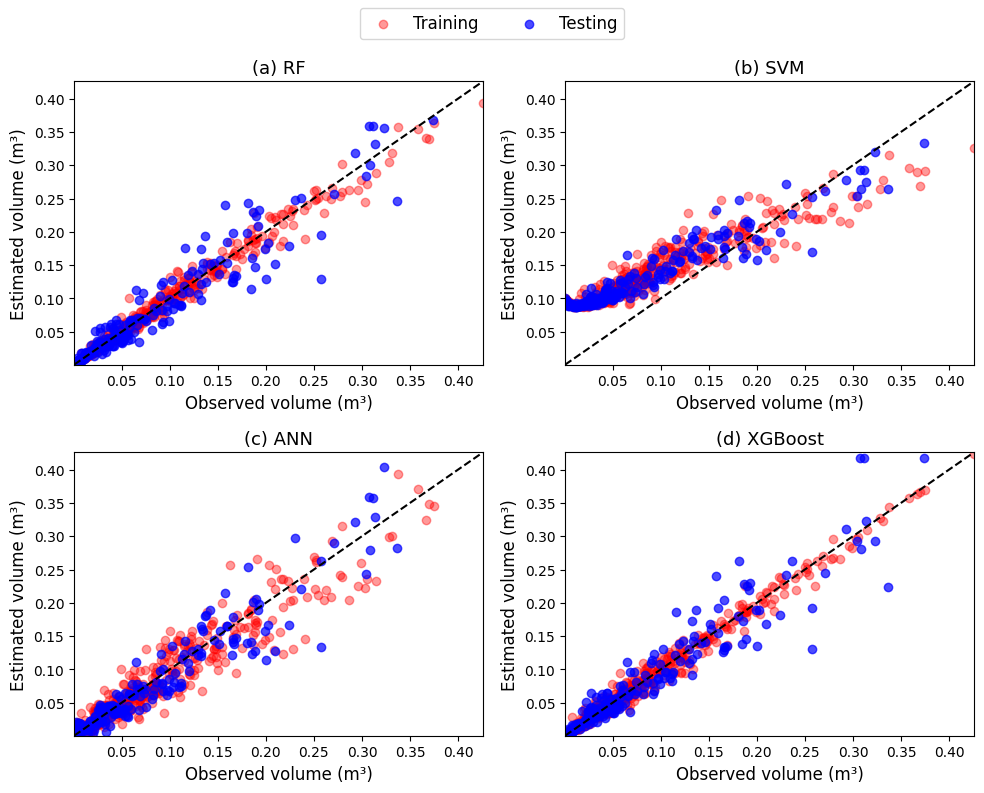

In [20]:
# Scatterplots for ML algorithms

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
})

# limites globais
min_val = min(y_train.min(), y_test.min())
max_val = max(y_train.max(), y_test.max())

def plot_model(ax, y_train, pred_train, y_test, pred_test, title):

    # treino
    ax.scatter(
        y_train,
        pred_train,
        color="red",
        alpha=0.4,
        label="Training"
    )

    # teste
    ax.scatter(
        y_test,
        pred_test,
        color="blue",
        alpha=0.7,
        label="Testing"
    )

    # linha 1:1
    ax.plot([min_val, max_val], [min_val, max_val], 'k--')

    ax.set_title(title)
    ax.set_xlabel("Observed volume (m³)")
    ax.set_ylabel("Estimated volume (m³)")

    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)


fig, axs = plt.subplots(2, 2, figsize=(10, 8))

plot_model(axs[0, 0], y_train, pred_rf_train, y_test, pred_rf_test, "(a) RF")
plot_model(axs[0, 1], y_train, pred_svm_train, y_test, pred_svm_test, "(b) SVM")
plot_model(axs[1, 0], y_train, pred_ann_train, y_test, pred_ann_test, "(c) ANN")
plot_model(axs[1, 1], y_train, pred_xgb_train, y_test, pred_xgb_test, "(d) XGBoost")

# legenda única
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

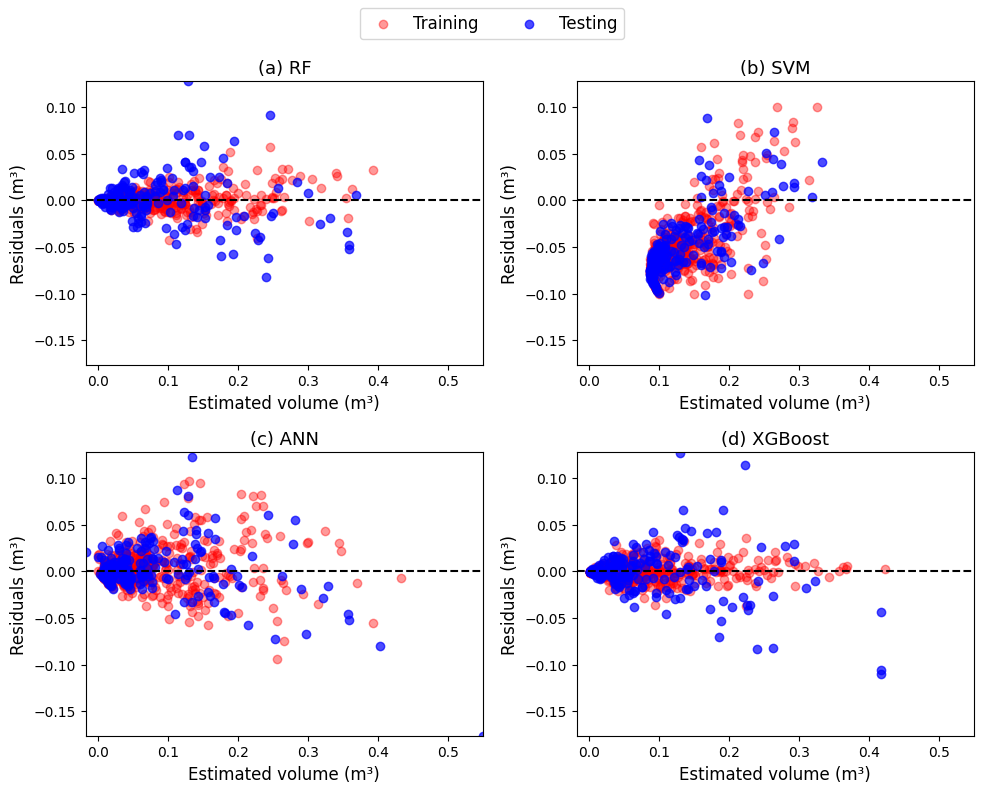

In [21]:
# Residuals for ML algorithms

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
})

# 🔹 calcular resíduos
res_rf_train = y_train - pred_rf_train
res_rf_test = y_test - pred_rf_test

res_svm_train = y_train - pred_svm_train
res_svm_test = y_test - pred_svm_test

res_ann_train = y_train - pred_ann_train
res_ann_test = y_test - pred_ann_test

res_xgb_train = y_train - pred_xgb_train
res_xgb_test = y_test - pred_xgb_test

# 🔹 limites globais (muito importante!)
min_x = min(
    pred_rf_train.min(), pred_rf_test.min(),
    pred_svm_train.min(), pred_svm_test.min(),
    pred_ann_train.min(), pred_ann_test.min(),
    pred_xgb_train.min(), pred_xgb_test.min()
)

max_x = max(
    pred_rf_train.max(), pred_rf_test.max(),
    pred_svm_train.max(), pred_svm_test.max(),
    pred_ann_train.max(), pred_ann_test.max(),
    pred_xgb_train.max(), pred_xgb_test.max()
)

min_y = min(
    res_rf_train.min(), res_rf_test.min(),
    res_svm_train.min(), res_svm_test.min(),
    res_ann_train.min(), res_ann_test.min(),
    res_xgb_train.min(), res_xgb_test.min()
)

max_y = max(
    res_rf_train.max(), res_rf_test.max(),
    res_svm_train.max(), res_svm_test.max(),
    res_ann_train.max(), res_ann_test.max(),
    res_xgb_train.max(), res_xgb_test.max()
)

def plot_residuals(ax, pred_train, res_train, pred_test, res_test, title):

    ax.scatter(pred_train, res_train, color="red", alpha=0.4, label="Training")
    ax.scatter(pred_test, res_test, color="blue", alpha=0.7, label="Testing")

    ax.axhline(0, color='black', linestyle='--')

    ax.set_title(title)
    ax.set_xlabel("Estimated volume (m³)")
    ax.set_ylabel("Residuals (m³)")

    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)


# 🔹 layout 2x2
fig, axs = plt.subplots(2, 2, figsize=(10, 8))

plot_residuals(axs[0, 0], pred_rf_train, res_rf_train, pred_rf_test, res_rf_test, "(a) RF")
plot_residuals(axs[0, 1], pred_svm_train, res_svm_train, pred_svm_test, res_svm_test, "(b) SVM")
plot_residuals(axs[1, 0], pred_ann_train, res_ann_train, pred_ann_test, res_ann_test, "(c) ANN")
plot_residuals(axs[1, 1], pred_xgb_train, res_xgb_train, pred_xgb_test, res_xgb_test, "(d) XGBoost")

# legenda única
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()